In [30]:
# Packages used throughout this project
import pandas as pd
import numpy as np

import seaborn as sns
sns.set_style("whitegrid")
import matplotlib.pyplot as plt

import lightgbm as lgb
from sklearn.preprocessing import OrdinalEncoder

In [31]:
# StateHoliday is both nominal and ordinal; it uses a, b, and c values to indicate the holiday as well as 0, which
# indicates no holiday on that specific day
# If Date follows unstandardized dates, pd.read_csv reads it as a column with object type, and that is not what we want
# Thus, we force our desired types
train = pd.read_csv("data/train.csv", dtype={"StateHoliday": str}, parse_dates=["Date"])
test = pd.read_csv("data/test.csv", dtype={"StateHoliday": str}, parse_dates=["Date"])
store = pd.read_csv("data/store.csv")

In [32]:
# Let's take a look at our data
# Luckily, train has no missing values
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[ns]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[ns](1), int64(7), object(1)
memory usage: 69.8+ MB


In [33]:
# test dataset doesn't contain customers
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Id             41088 non-null  int64         
 1   Store          41088 non-null  int64         
 2   DayOfWeek      41088 non-null  int64         
 3   Date           41088 non-null  datetime64[ns]
 4   Open           41077 non-null  float64       
 5   Promo          41088 non-null  int64         
 6   StateHoliday   41088 non-null  object        
 7   SchoolHoliday  41088 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(5), object(1)
memory usage: 2.5+ MB


In [34]:
# Four possible combinations of Open and sales
# Open=1, Sales=0
# My final verdict is that they are not anomalies, and I will keep them. The model can learn from these samples.
open_zero_sales = train[(train["Open"] == 1) & (train["Sales"] == 0)]
print(len(open_zero_sales), "rows open with zero sales")
print()

# concentrated in a few stores, or spread out?
print(open_zero_sales["Store"].value_counts())
print()

54 rows open with zero sales

Store
28      3
364     2
102     2
983     2
1100    2
1017    2
1039    2
665     2
25      2
623     2
835     2
339     2
589     1
948     1
681     1
700     1
353     1
927     1
259     1
391     1
663     1
232     1
971     1
850     1
327     1
303     1
699     1
708     1
357     1
227     1
548     1
238     1
387     1
986     1
882     1
887     1
925     1
57      1
661     1
674     1
762     1
Name: count, dtype: int64



In [35]:
# The test dataset has 11 missing values for "Open". All the samples belong to the same store, 622
test_missing_values = test[test['Open'].isna()]
test_missing_values

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
479,480,622,4,2015-09-17,NaN,1,0,0
1335,1336,622,3,2015-09-16,NaN,1,0,0
2191,2192,622,2,2015-09-15,NaN,1,0,0
3047,3048,622,1,2015-09-14,NaN,1,0,0
4759,4760,622,6,2015-09-12,NaN,0,0,0
5615,5616,622,5,2015-09-11,NaN,0,0,0
6471,6472,622,4,2015-09-10,NaN,0,0,0
7327,7328,622,3,2015-09-09,NaN,0,0,0
8183,8184,622,2,2015-09-08,NaN,0,0,0
9039,9040,622,1,2015-09-07,NaN,0,0,0


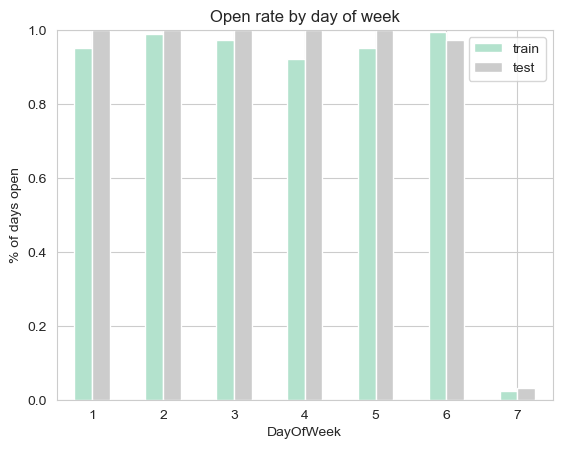

In [36]:
# Let's see how often the stores are open on each weak day
train_open_rate = train.groupby("DayOfWeek")["Open"].mean().rename("train")
test_open_rate = test.groupby("DayOfWeek")["Open"].mean().rename("test")
open_rates = pd.concat([train_open_rate, test_open_rate], axis=1)
open_rates.plot(kind="bar", rot=0, colormap="Pastel2")
plt.ylabel("% of days open")
plt.title("Open rate by day of week")
plt.ylim(0, 1)
plt.show()

In [37]:
test_missing_values = test.loc[test["Open"].isna()]
affected_store = test_missing_values["Store"].unique()
# Question: what is the difference between train.Store and train["Store"]
affected_store_history = train[train.Store == affected_store[0]]
affected_store_open_rate = affected_store_history.groupby("DayOfWeek")["Open"].mean().rename("Store")
affected_days = test_missing_values.loc[test_missing_values["Store"] == affected_store[0], "DayOfWeek"].unique()
# I did this because I had doubts about stores being open on Saturday
for day in affected_days:
    rate = affected_store_open_rate.get(day, np.nan)
    print(f"DayOfWeek={day}: this store was historically open {rate:.1%} of the time on that day")

DayOfWeek=4: this store was historically open 94.1% of the time on that day
DayOfWeek=3: this store was historically open 97.8% of the time on that day
DayOfWeek=2: this store was historically open 99.3% of the time on that day
DayOfWeek=1: this store was historically open 95.5% of the time on that day
DayOfWeek=6: this store was historically open 100.0% of the time on that day
DayOfWeek=5: this store was historically open 95.6% of the time on that day


In [38]:
# Since the store is open on the missing days
test["Open"] = test["Open"].fillna(1)

In [39]:
# Store dataset is missing values for CompetitionDistance, CompetitionOpenSinceMonth, CompetitionOpenSinceYear, Promo2SinceWeek, Promo2SinceYear,
# and PromoInterval
# They are not missing at random, so we will take care of them later in the feature engineering step
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [40]:
# Quick sanity check: PromoInterval should be missing exactly where Promo2==0.
print(store.loc[store.Promo2 == 0, "PromoInterval"].isna().mean())  # expect 1.0
print(store.loc[store.Promo2 == 1, "PromoInterval"].isna().mean())  # expect 0.0

1.0
0.0


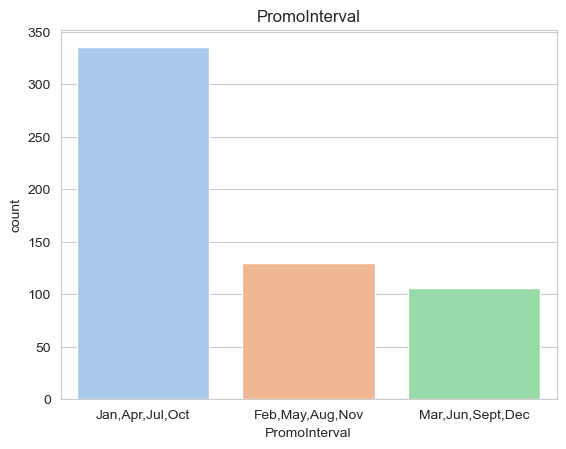

In [41]:
store["PromoInterval"].dropna().value_counts()
sns.countplot(data=store, x="PromoInterval", hue="PromoInterval", legend=False, palette="pastel")
plt.title("PromoInterval")
plt.show()

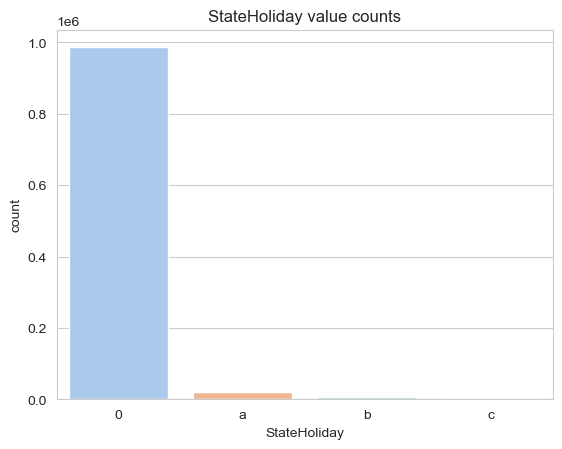

In [42]:
sns.countplot(data=train, x="StateHoliday", hue="StateHoliday", legend=False, palette="pastel")
plt.title("StateHoliday value counts")
plt.show()

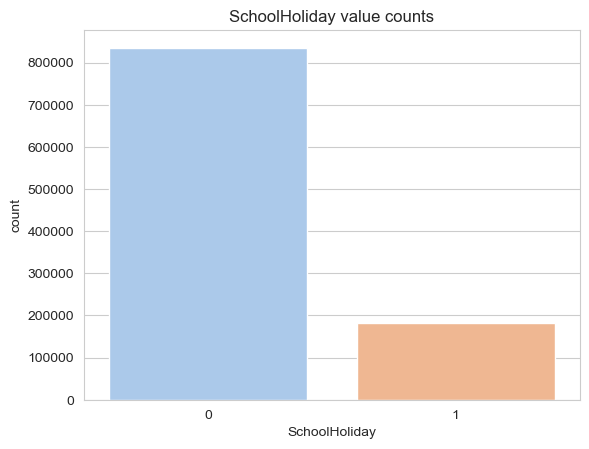

In [43]:
sns.countplot(data=train, x="SchoolHoliday", hue="SchoolHoliday", legend=False, palette="pastel")
plt.title("SchoolHoliday value counts")
plt.show()

In [44]:
# Date; we need this later to split train and validation, and to train our models
# The test set includes August and September
print("\nTrain date range:", train.Date.min(), "to", train.Date.max())
print("Test date range:", test.Date.min(), "to", test.Date.max())


Train date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
Test date range: 2015-08-01 00:00:00 to 2015-09-17 00:00:00


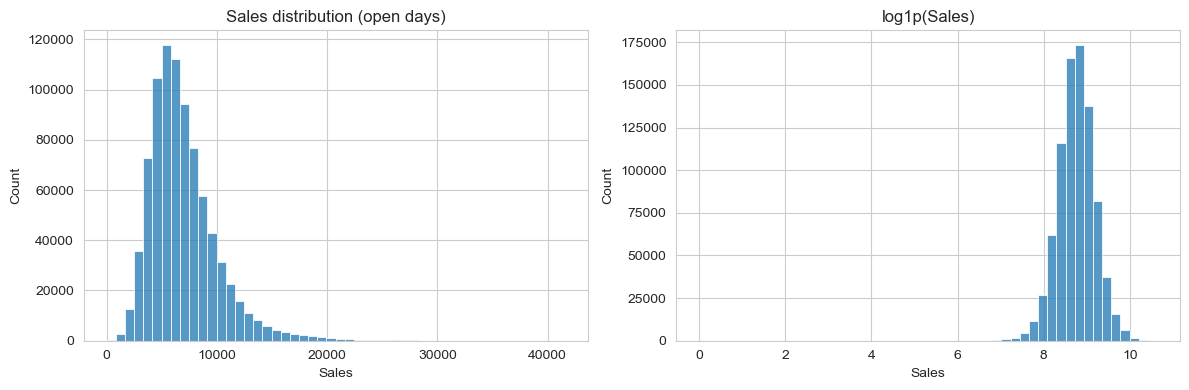

In [45]:
# Target distribution: Sales is right-skewed (a handful of big shopping
# days pull the tail). This matters because the competition metric (RMSPE,
# root mean squared percentage error) and most tree/linear models behave
# better on a log-transformed target for skewed money/count data.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train.loc[train.Open == 1, "Sales"], bins=50, ax=ax[0])
ax[0].set_title("Sales distribution (open days)")
sns.histplot(np.log1p(train.loc[train.Open == 1, "Sales"]), bins=50, ax=ax[1])
ax[1].set_title("log1p(Sales)")
plt.tight_layout()
plt.show()

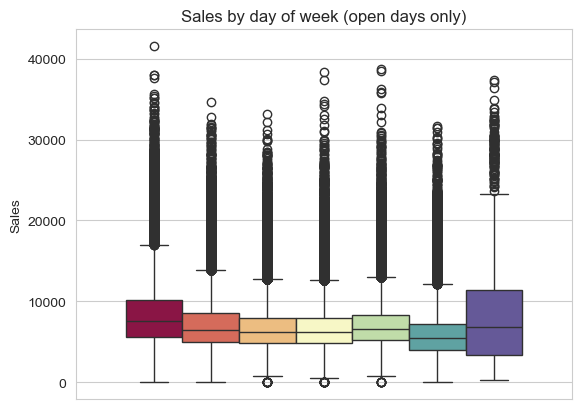

In [46]:
# Sales by day of week
sns.boxplot(data=train[train.Open == 1], hue="DayOfWeek", y="Sales", palette="Spectral", legend=False)
plt.title("Sales by day of week (open days only)")
plt.show()

In [47]:
# store.csv is one row per store. This is a many-to-one left join: each of
# the ~1,115 stores gets matched to its ~942 daily rows in train. The row
# count of the result equals len(train), not len(train) * len(store)
# Downcast dtypes before merging to keep memory low and keep it low after.
for df in (train, test):
    df["DayOfWeek"] = df["DayOfWeek"].astype("int8")
    df["Open"] = df["Open"].astype("Int8")  
    df["Promo"] = df["Promo"].astype("int8")
    df["SchoolHoliday"] = df["SchoolHoliday"].astype("int8")
    df["StateHoliday"] = df["StateHoliday"].astype("category")

store["StoreType"] = store["StoreType"].astype("category")
store["Assortment"] = store["Assortment"].astype("category")

train_full = train.merge(store, on="Store", how="left")
test_full = test.merge(store, on="Store", how="left")

# sanity check
print(train_full.memory_usage(deep=True).sum() / 1e6, "MB")  

138.45737 MB


In [48]:
def feature_engineering(df, store_df):
    df = df.copy()

    #date
    df["Year"] = df.Date.dt.year
    df["Month"] = df.Date.dt.month
    df["Day"] = df.Date.dt.day
    df["WeekOfYear"] = df.Date.dt.isocalendar().week.astype(int)

    # Missing CompetitionDistance is rare and means "no known competitor" (there are only 3 missing values)
    # imputing it with a large value, not the median, so the model reads it as
    # "far away" rather than "typical distance."
    df["CompetitionDistance"] = df["CompetitionDistance"].fillna(
        df["CompetitionDistance"].max() * 2
    )

    # Missing CompetitionOpenSince means the open date is unknown
    # treat "months since competition opened" as 0 when unknown, and keep a flag.
    comp_open = pd.to_datetime(
        dict(
            year=df["CompetitionOpenSinceYear"],
            month=df["CompetitionOpenSinceMonth"],
            day=1,
        ),
        errors="coerce",
    )
    df["CompetitionOpenMonths"] = (
        (df["Date"] - comp_open).dt.days / 30
    ).clip(lower=0).fillna(0)
    df["HasCompetitionOpenDate"] = comp_open.notna().astype("int8")

    # Promo2: missing here isn't "unknown," it's "not applicable"
    # Build a clean IsPromo2Active flag instead of trying to impute the
    # since-week/since-year columns directly.
    month_map = {
        1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
        7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec",
    }
    df["_MonthStr"] = df["Month"].map(month_map)
    promo2_since = pd.to_datetime(
        df["Promo2SinceYear"].astype("Int64").astype(str)
        + df["Promo2SinceWeek"].astype("Int64").astype(str).str.zfill(2)
        + "1",
        format="%Y%W%w",
        errors="coerce",
    )
    is_after_start = (df["Date"] >= promo2_since).fillna(False)
    in_interval = df.apply(
        lambda r: isinstance(r["PromoInterval"], str)
        and r["_MonthStr"] in r["PromoInterval"].split(","),
        axis=1,
    )
    df["IsPromo2Active"] = (
        (df["Promo2"] == 1) & is_after_start & in_interval
    ).astype("int8")
    df = df.drop(columns=["_MonthStr"])

    # state holiday: collapse to a clean flag + keep the category 
    df["IsStateHoliday"] = (df["StateHoliday"] != "0").astype("int8")

    return df

train_fe = feature_engineering(train_full, store)
test_fe = feature_engineering(test_full, store)

# Drop rows where the store is closed; Sales is 0 by definition on those days, and they're excluded from scoring, so they're noise for training
train_fe = train_fe[train_fe.Open == 1].copy()

# Log-transform the target; Remember to np.expm1() predictions
# back before evaluating or submitting.
train_fe["SalesLog"] = np.log1p(train_fe["Sales"])

In [49]:
def lift_ratio(df, condition_mask, name):
    cond_avg = df.loc[condition_mask].groupby("Store")["Sales"].mean()
    noncond_avg = df.loc[~condition_mask].groupby("Store")["Sales"].mean()
    return (cond_avg / noncond_avg).rename(name)

def add_shop_and_day_aggregates(train_full, train_open):
    shopavg_open = train_full.groupby("Store")["Open"].mean().rename("shopavg_open")
    shopavg_schoolholiday = train_full.groupby("Store")["SchoolHoliday"].mean().rename("shopavg_schoolholiday")
    shopavg_salespercustomer = (
        (train_open["Sales"] / train_open["Customers"])
        .groupby(train_open["Store"]).mean().rename("shopavg_salespercustomer")
    )
    shopsales_promo = lift_ratio(train_open, train_open["Promo"] == 1, "shopsales_promo")
    shopsales_holiday = lift_ratio(train_open, train_open["IsStateHoliday"] == 1, "shopsales_holiday")
    shopsales_saturday = lift_ratio(train_open, train_open["DayOfWeek"] == 6, "shopsales_saturday")

    return pd.concat([
        shopavg_open, shopavg_schoolholiday, shopavg_salespercustomer,
        shopsales_promo, shopsales_holiday, shopsales_saturday,
    ], axis=1).reset_index().rename(columns={"index": "Store"})

def add_holiday_week_counts(train_df, test_df):
    train_df = train_df.copy()
    test_df = test_df.copy()
    train_df["_is_test"] = 0
    test_df["_is_test"] = 1
    # this causes Id to be converted to string
    combined = pd.concat([train_df, test_df], sort=False, ignore_index=True)
    combined = combined.sort_values(["Store", "Date"]).reset_index(drop=True)

    g = combined.groupby("Store")["IsStateHoliday"]
    combined["holidays_thisweek"] = g.transform(lambda s: s.rolling(7, center=True, min_periods=1).sum())
    combined["holidays_lastweek"] = g.shift(7).groupby(combined["Store"]).transform(
        lambda s: s.rolling(7, min_periods=1).sum()
    )
    combined["holidays_nextweek"] = g.shift(-7).groupby(combined["Store"]).transform(
        lambda s: s.rolling(7, min_periods=1).sum()
    )
    for c in ["holidays_thisweek", "holidays_lastweek", "holidays_nextweek"]:
        combined[c] = combined[c].fillna(0)

    train_out = combined[combined["_is_test"] == 0].drop(columns=["_is_test"])
    test_out = combined[combined["_is_test"] == 1].drop(columns=["_is_test"])
    return train_out, test_out

def add_dayavg_openyesterday(train_df, test_df):
    train_df = train_df.copy()
    test_df = test_df.copy()
    train_df["_is_test"] = 0
    test_df["_is_test"] = 1
    # this causes Id to be converted string
    combined = pd.concat([train_df, test_df], sort=False, ignore_index=True)
    combined = combined.sort_values("Date")
    daily_open_rate = combined.groupby("Date")["Open"].mean()
    combined["dayavg_openyesterday"] = combined["Date"].map(
        daily_open_rate.reindex(daily_open_rate.index).shift(1)
    )
    combined["dayavg_openyesterday"] = combined["dayavg_openyesterday"].fillna(1.0)
    combined = combined.sort_values(["Store", "Date"])
    train_out = combined[combined["_is_test"] == 0].drop(columns=["_is_test"])
    test_out = combined[combined["_is_test"] == 1].drop(columns=["_is_test"])
    return train_out, test_out

shop_aggs = add_shop_and_day_aggregates(train_full, train_fe)
train_fe = train_fe.merge(shop_aggs, on="Store", how="left")
test_fe = test_fe.merge(shop_aggs, on="Store", how="left")

train_fe, test_fe = add_holiday_week_counts(train_fe, test_fe)
train_fe, test_fe = add_dayavg_openyesterday(train_fe, test_fe)

In [50]:
drop_cols_train = ["Customers", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2SinceWeek",
                   "Promo2SinceYear", "PromoInterval", "StateHoliday"]
drop_cols_test = drop_cols_train + []

train_fe = train_fe.drop(columns=[c for c in drop_cols_train if c in train_fe.columns])
test_fe = test_fe.drop(columns=[c for c in drop_cols_test if c in test_fe.columns])

In [51]:
# test.csv spans 6 weeks (2015-08-01 to 2015-09-17) 
# our validation set should be the same length, taken from the end of train
# so it behaveslike a genuine forecast rather than an interpolation
cutoff = train_fe["Date"].max() - pd.Timedelta(weeks=6)

X_train = train_fe[train_fe["Date"] <= cutoff]
X_val = train_fe[train_fe["Date"] > cutoff]

print("Train:", X_train.Date.min(), "-", X_train.Date.max(), len(X_train))
print("Val:  ", X_val.Date.min(), "-", X_val.Date.max(), len(X_val))

Train: 2013-01-01 00:00:00 - 2015-06-19 00:00:00 804110
Val:   2015-06-20 00:00:00 - 2015-07-31 00:00:00 40282


In [52]:
# Naive baseline: for each store, predict this day-of-week's sales as the
# median of that store's sales on the same day-of-week within the training time scale window
dow_median = (X_train.groupby(["Store", "DayOfWeek"])["Sales"].median().rename("baseline_pred"))
val_baseline = X_val.merge(dow_median, on=["Store", "DayOfWeek"], how="left")

def rmspe(y_true, y_pred):
    # The competition's actual metric — percentage error, so it penalizes
    # relative misses evenly across small and large stores.
    mask = y_true != 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

baseline_score = rmspe(val_baseline["Sales"].values, val_baseline["baseline_pred"].values)
print("Baseline RMSPE:", baseline_score)

Baseline RMSPE: 0.24508302605728424


In [53]:
#model
features = ["Store", "DayOfWeek", "Promo", "SchoolHoliday", "IsStateHoliday",
    "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenMonths",
    "HasCompetitionOpenDate", "Promo2", "IsPromo2Active",
    "Year", "Month", "Day", "WeekOfYear",
    "shopavg_open", "shopavg_schoolholiday", "shopavg_salespercustomer",
    "shopsales_promo", "shopsales_holiday", "shopsales_saturday",
    "holidays_thisweek", "holidays_lastweek", "holidays_nextweek"]
cat_features = ["Store", "DayOfWeek", "StoreType", "Assortment"]

enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_train_enc = X_train[features].copy()
X_val_enc = X_val[features].copy()
X_train_enc[cat_features] = enc.fit_transform(X_train[cat_features])
X_val_enc[cat_features] = enc.transform(X_val[cat_features])

train_set = lgb.Dataset(X_train_enc, label=X_train["SalesLog"], categorical_feature=cat_features)
val_set = lgb.Dataset(X_val_enc, label=X_val["SalesLog"], categorical_feature=cat_features)

params = {
    "objective": "regression",
    "metric": "rmse",
    "learning_rate": 0.05,
    "verbose": -1,
    "seed": 42,
    "deterministic": True,
}
model = lgb.train(
    params,
    train_set,
    num_boost_round=10000,
    valid_sets=[val_set],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
)

val_pred_log = model.predict(X_val_enc, num_iteration=model.best_iteration)
# undo the log1p
val_pred = np.expm1(val_pred_log)  
model_score = rmspe(X_val["Sales"].values, val_pred)
print("LightGBM RMSPE:", model_score, " vs baseline:", baseline_score)

Training until validation scores don't improve for 100 rounds
[100]	valid_0's rmse: 0.150441
[200]	valid_0's rmse: 0.136456
[300]	valid_0's rmse: 0.131392
[400]	valid_0's rmse: 0.127453
[500]	valid_0's rmse: 0.123867
[600]	valid_0's rmse: 0.122609
[700]	valid_0's rmse: 0.121347
[800]	valid_0's rmse: 0.120882
[900]	valid_0's rmse: 0.119688
[1000]	valid_0's rmse: 0.11904
[1100]	valid_0's rmse: 0.118836
[1200]	valid_0's rmse: 0.118693
Early stopping, best iteration is:
[1192]	valid_0's rmse: 0.118455
LightGBM RMSPE: 0.12795897326303735  vs baseline: 0.24508302605728424


In [54]:
final_rounds = model.best_iteration
print("Refitting for", final_rounds, "rounds on the full training set")
 
X_full_enc = train_fe[features].copy()
X_full_enc[cat_features] = enc.transform(X_full_enc[cat_features]) 
full_set = lgb.Dataset(X_full_enc, label=train_fe["SalesLog"], categorical_feature=cat_features)
 
final_model = lgb.train(params, full_set, num_boost_round=final_rounds)

Refitting for 1192 rounds on the full training set


In [55]:
importance = pd.DataFrame({
    "feature": X_train_enc.columns,
    "gain": final_model.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)
importance

,feature,gain
0,Store,979285.702990
2,Promo,258582.562596
1,DayOfWeek,106860.248876
14,Day,41224.908874
15,WeekOfYear,39047.952896
21,shopsales_saturday,31337.597033
13,Month,16837.535958
12,Year,9270.223769
16,shopavg_open,3426.755828
3,SchoolHoliday,3197.836738


<Axes: xlabel='feature'>

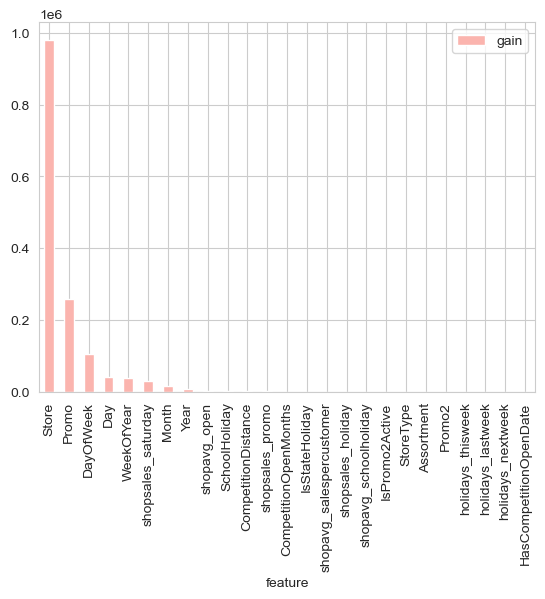

In [56]:
# Plot feature importance using Gain
importance.plot(kind="bar", x="feature", y="gain", colormap="Pastel1")

In [57]:
print(test_fe["Open"].value_counts(dropna=False))
 
test_open_mask = test_fe["Open"] == 1
test_open = test_fe[test_open_mask].copy()
test_closed = test_fe[~test_open_mask].copy()
 
X_test_open_enc = test_open[features].copy()
X_test_open_enc[cat_features] = enc.transform(X_test_open_enc[cat_features])
test_open["Sales"] = np.expm1(final_model.predict(X_test_open_enc))
 
test_closed["Sales"] = 0.0
 
submission = pd.concat([test_open, test_closed])[["Id", "Sales"]].sort_values("Id")
# enforcing Id to be int32
submission["Id"] = submission["Id"].astype(int)
submission.to_csv("submission.csv", index=False)
print(submission.head())
print("Closed-store rows forced to 0 in submission:", (submission["Sales"] == 0).sum())

Open
1    35104
0     5984
Name: count, dtype: Int64
        Id        Sales
844439   1  4128.812000
844487   2  7451.450486
844535   3  8741.381980
844583   4  7595.646341
844631   5  7366.349927
Closed-store rows forced to 0 in submission: 5984
